In [1]:
# Global imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Global imports applied successfully.")

Global imports applied successfully.


In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the overall theme and default color palette
sns.set_theme(style="whitegrid", palette="muted")

# Set default figure dimensions: width=8 inches, height=4 inches
plt.rcParams['figure.figsize'] = (8, 4)

# Set default chart title font size to 12 points
plt.rcParams['axes.titlesize'] = 12

# Set default X-axis and Y-axis label font size to 10 points
plt.rcParams['axes.labelsize'] = 10

# Set default figure resolution to 120 DPI
plt.rcParams['figure.dpi'] = 120

print("Visualization settings applied successfully.")

Visualization settings applied successfully.


## 1.Multi-Index DataFrames & Hierarchial Slicing

multi-indexed series
 region  Year
North   2024    100
        2025    150
South   2024    200
        2025    250
dtype: int64
____________________________________________________________


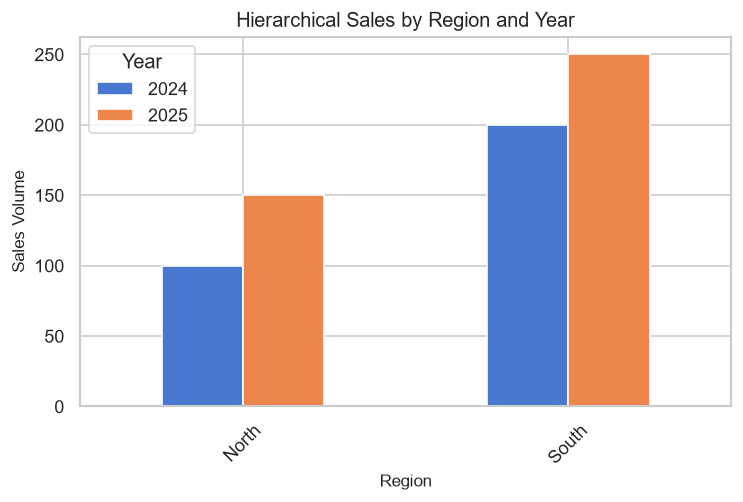

In [ ]:
arrays=[['North','North','South','South'],[2024,2025,2024,2025]]
sales=[100,150,200,250]
# print(arrays)
# print(sales)

# create a multiindex from arrays
index=pd.MultiIndex.from_arrays(arrays,names=('region','Year'))
# print(index)
my_sales_region_wise = pd.Series(sales, index=index)
print("multi-indexed series\n",my_sales_region_wise)
print("_" * 60)

# hierarchical indexing
# print("North region sales\n", my_sales_region_wise. loc['North'])
# print("_" * 60)
# print("North region sales[0]", my_sales_region_wise.iloc[0],sep="\t:\t")
# print("North region sales[0:1]:-", my_sales_region_wise.iloc[0:1],sep="\n")
# print("_" * 60)

df_plot = my_sales_region_wise.unstack(level='Year')
# print("unstacked DataFrame\n", df_plot)
# visualization
ax = df_plot.plot(kind='bar',figsize=(7,4))
plt.title('Hierarchical Sales by Region and Year')
plt.xlabel('Region')
plt.ylabel('Sales Volume')
plt.xticks(rotation=45) # x-axis labels rotation
plt.show()

### 2. Vectorized strings & regex operations


In [29]:
data = {'address': ['100 Main St, Suite 400, NY 10001', '456 Market Rd, CA 90210', '789 Broadway, NY 10001', '321 Pine Rd, CA 90210']}
df = pd.DataFrame(data)
# print(df)

# vectorized regex extraction
# df['zip_code'] = df['address'].str.extract(r'(\b\d{5}\b)')
df['zip_code'] = df['address'].str.extract(r'(\d{5})')
df['clean_street'] = df['address'].str.replace(r',.*','',regex=True)
print(df)

                            address zip_code   clean_street
0  100 Main St, Suite 400, NY 10001    10001    100 Main St
1           456 Market Rd, CA 90210    90210  456 Market Rd
2            789 Broadway, NY 10001    10001   789 Broadway
3             321 Pine Rd, CA 90210    90210    321 Pine Rd


### 3. Transform pipelines


dept   
HR    0   -5333.333333
      1    6666.666667
      4   -1333.333333
IT    2   -7666.666667
      3    7333.333333
      5     333.333333
Name: salary, dtype: float64
____________________________________________________________
  dept  salary     division   z_score  z_score1
0   HR   50000      Support -0.872872 -0.872872
1   HR   62000      Support  1.091089  1.091089
2   IT   80000  Engineering -1.021466 -1.021466
3   IT   95000  Engineering  0.977054  0.977054
4   HR   54000      Support -0.218218 -0.218218
5   IT   88000  Engineering  0.044412  0.044412


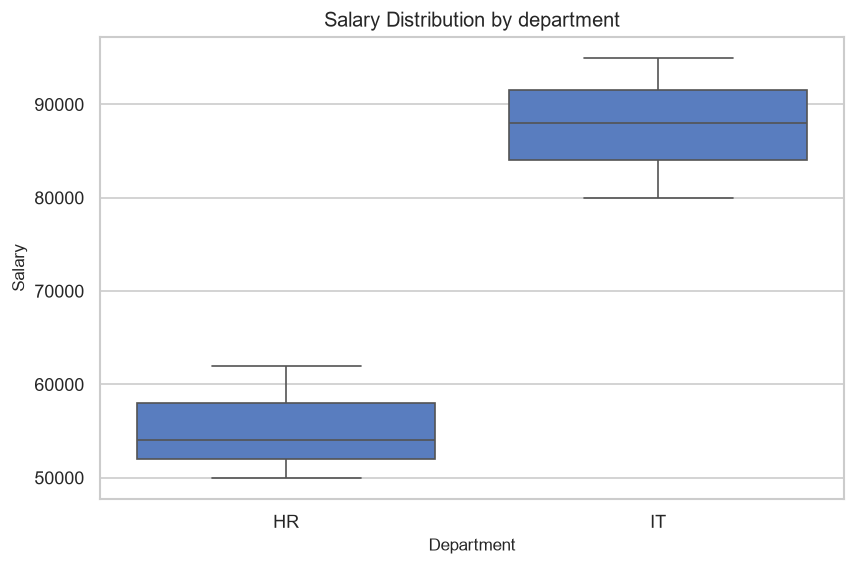

In [ ]:
df_pipe = pd.DataFrame({
    'dept': ['HR', 'HR', 'IT', 'IT', 'HR', 'IT'],
    'salary': [50000, 62000, 80000, 95000, 54000, 88000]
})
# print(df_pipe)
tier_map = {'HR': 'Support', 'IT': 'Engineering'}
df_pipe['division'] = df_pipe['dept'].map(tier_map)
df_pipe['z_score'] = df_pipe.groupby('dept')['salary'].transform(lambda x: (x - x.mean()) / x.std())
df_pipe['z_score1'] = (
    df_pipe.groupby('dept')['salary']
    .apply(lambda x: (x - x.mean()) / x.std())
    .reset_index(level=0, drop=True)
)
result = df_pipe.groupby('dept')['salary'].apply(
    lambda x: x - x.mean()
)
# print(result)
print("_" * 60)
print(df_pipe)

# visuvalization
plt.figure(figsize=(8,5))
sns.boxplot(x='dept',y='salary',data=df_pipe)
plt.title('Salary Distribution by department')
plt.xlabel('Department')
plt.ylabel('Salary')
plt.show()

### 4. memory optimization and data type downcasting

In [45]:
df_mem = pd.DataFrame({
    'id': np.arange(1000, dtype='int64'),
    'category': ['A', 'B', 'C', 'A'] * 250
})
print(df_mem.dtypes)
# print(df_mem.head())

print("Before Optimization (Bytes):\n", df_mem.memory_usage(deep=True))

# Optimize memory usage by converting 'category' column to 'category' dtype
df_mem['category'] = df_mem['category'].astype('category')
df_mem['id'] = df_mem['id'].astype('int32')
print(df_mem.dtypes)
print("After Optimization (Bytes):\n", df_mem.memory_usage(deep=True))

id          int64
category      str
dtype: object
Before Optimization (Bytes):
 Index        132
id          8000
category    9000
dtype: int64
id             int32
category    category
dtype: object
After Optimization (Bytes):
 Index        132
id          4000
category    1028
dtype: int64


### 5. High performance query

In [46]:
#eval and query
np.random.seed(42)
df_perf = pd.DataFrame({
    'a': np.random.rand(1000),
    'b': np.random.rand(1000),
    'c': np.random.rand(1000)
})

# High-performance eval & query execution
df_perf.eval('d = (a+b) / c', inplace=True)
filtered_df = df_perf.query('a > 0.5 and b < 0.5')
print(filtered_df.head())

           a         b         c          d
8   0.601115  0.249668  0.065366  13.015650
9   0.708073  0.489425  0.487571   2.456047
25  0.785176  0.474214  0.260158   4.840871
28  0.592415  0.319100  0.256530   3.553248
30  0.607545  0.037008  0.198098   3.253711
